<a href="https://colab.research.google.com/github/PeterPan2009/ML-Projects/blob/main/Zomato_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#what type of resturants do the majority of customers order from?
#How many votes has each type of resturant received from customers?
#What are the ratings that the majority of resturnts have received?
#Zomato has observed that most couples order most of their food online. What is their average spending on each order?
#Which mode (online or offline) has recived the maximum rating?
#Which type of resturant received more offline orders, so that Zomato can present customer with some good offers?

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
path = kagglehub.dataset_download("ruchikakumbhar/zomato-dataset")
csv_path = os.path.join(path, "Zomato-data-.csv")
df = pd.read_csv(csv_path, encoding='latin-1')
df.head()

100%|██████████| 2.48k/2.48k [00:00<00:00, 3.09MB/s]

Extracting files...


,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [ ]:
df

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet
...,...,...,...,...,...,...,...
143,Melting Melodies,No,No,3.3/5,0,100,Dining
144,New Indraprasta,No,No,3.3/5,0,150,Dining
145,Anna Kuteera,Yes,No,4.0/5,771,450,Dining
146,Darbar,No,No,3.0/5,98,800,Dining


In [ ]:
#what type of resturants do the majority of customers order from?
#convert datea type for column Rate
def handlerate (value):
  value = str(value).split('/')
  value = value[0];
  return float (value)

df['rate'] = df['rate'].apply(handlerate)
print (df.head())


                    name online_order book_table  rate  votes  \
0                  Jalsa          Yes        Yes   4.1    775   
1         Spice Elephant          Yes         No   4.1    787   
2        San Churro Cafe          Yes         No   3.8    918   
3  Addhuri Udupi Bhojana           No         No   3.7     88   
4          Grand Village           No         No   3.8    166   

   approx_cost(for two people) listed_in(type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   name                         148 non-null    object 
 1   online_order                 148 non-null    object 
 2   book_table                   148 non-null    object 
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    object 
dtypes: float64(1), int64(2), object(4)
memory usage: 8.2+ KB


Text(0.5, 0, 'Type of resturant')

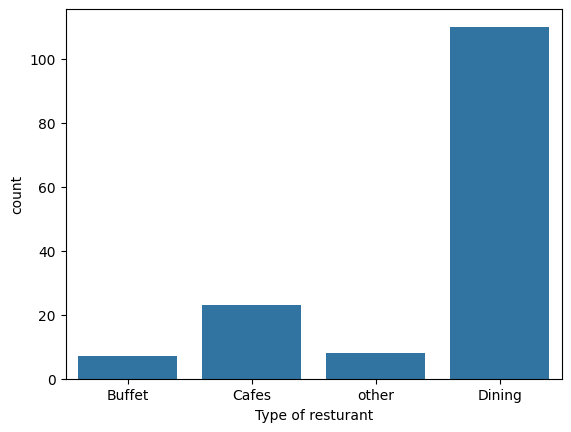

In [ ]:
#what type of resturants do the majority of customers order from? - Dinning
sns.countplot(x=df['listed_in(type)'])
plt.xlabel ("Type of resturant")

Text(0, 0.5, 'Votes')

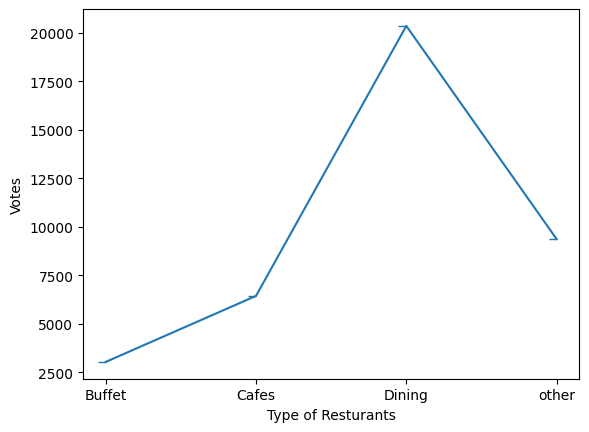

In [ ]:
#How many votes has each type of resturant received from customers? Dinning received most votes
total_votes = df.groupby('listed_in(type)')['votes'].sum()
result=pd.DataFrame({'votes': total_votes})
plt.plot(result,marker =0)
plt.xlabel('Type of Resturants')
plt.ylabel('Votes')

In [ ]:
total_votes

,listed_in(type),votes
0,Buffet,3028
1,Cafes,6434
2,Dining,20363
3,other,9367


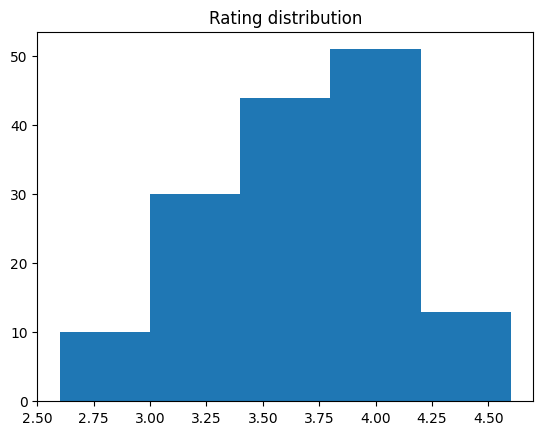

In [61]:
#What are the ratings that the majority of resturnts have received? most ratings are between 3.5 - 4
plt.hist(df['rate'],bins =5)
plt.title('Rating distribution')
plt.show()

<Axes: xlabel='approx_cost(for two people)', ylabel='count'>

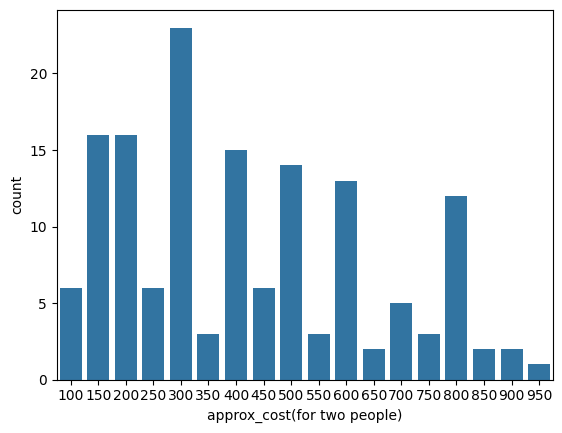

In [76]:
#Zomato has observed that most couples order most of their food online. What is their average spending on each order? - majority couples place orders about 300
sns.countplot(x=df['approx_cost(for two people)'])

<Axes: xlabel='online_order', ylabel='rate'>

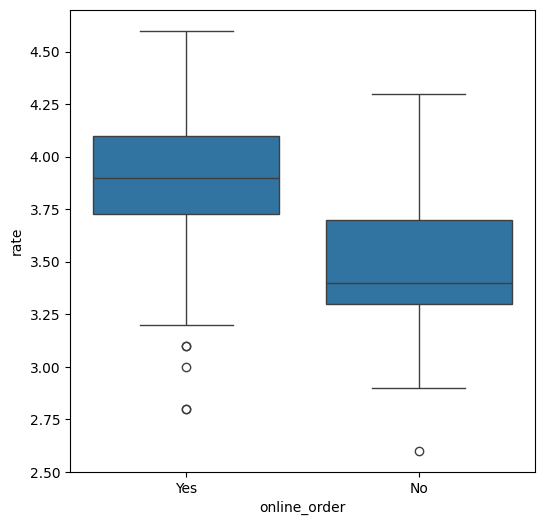

In [107]:
#Which mode (online or offline) has recived the maximum rating? Online orders received higher ratings
plt.figure(figsize = (6,6))
sns.boxplot(x='online_order', y = 'rate', data = df)


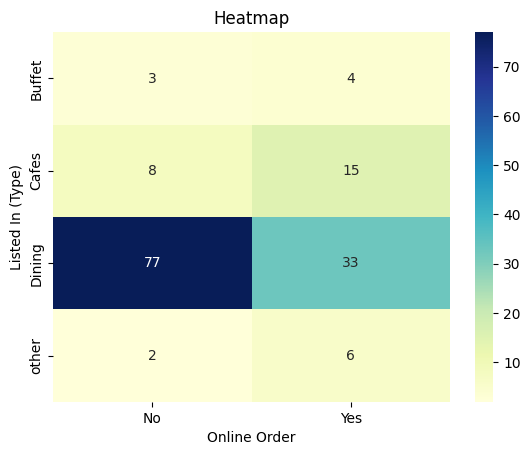

In [115]:
#Which type of resturant received more offline orders, so that Zomato can present customer with some good offers? Dinning order received more offline orders
pivot_table= df.pivot_table(index='listed_in(type)', columns='online_order', aggfunc= 'size', fill_value =0)
sns.heatmap(pivot_table, annot=True, cmap="YlGnBu", fmt='d')
plt.title ('Heatmap')
plt.xlabel('Online Order')
plt.ylabel('Listed In (Type)')
plt.show()